# 03 — Baseline Forecast

**Goal:** establish honest benchmarks for predicting daily nationwide oblast-level alarm count.  
No ML libraries — pure `pandas` / `numpy` only.

**Target variable:** `n_alarms` — total oblast-level alarms across all 25 oblasts per calendar day (Kyiv time).

Three baselines:
| # | Name | Formula |
|---|------|---------|
| 1 | Naive persistence | `pred[t] = actual[t-1]` |
| 2 | 7-day rolling mean | `pred[t] = mean(actual[t-7 … t-1])` |
| 3 | Weekly seasonal naive | `pred[t] = actual[t-7]` |

Metrics: **MAE** and **RMSE** on a 60-day held-out test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

## 1. Load daily counts

In [2]:
ANALYSIS_END = '2025-08-31'

dc = pd.read_csv('../data/daily_counts.csv', parse_dates=['date'])
dc = dc.sort_values('date').set_index('date')

# Clip BEFORE anything else — data after ANALYSIS_END is a collection artifact (near-zero)
dc = dc.loc[:ANALYSIS_END]

# Fill any zero-alarm days that were absent from the CSV
full_idx = pd.date_range(dc.index.min(), dc.index.max(), freq='D')
dc = dc.reindex(full_idx, fill_value=0)
dc.index.name = 'date'

print(f'Shape: {dc.shape}')
print(f'Date range: {dc.index.min().date()}  →  {dc.index.max().date()}')
dc.describe().round(1)

Shape: (1266, 1)
Date range: 2022-03-15  →  2025-08-31


,n_alarms
count,1266.0
mean,50.0
std,22.5
min,0.0
25%,35.0
50%,48.0
75%,62.0
max,189.0


## 2. Train / test split

> **Never shuffle time-series data before splitting.** Shuffling leaks future information into training — the model would see what happened after its supposed cutoff date.  
> We always split by date: everything before the cutoff = train, everything after = test.

We start from `2022-05-01` to skip the potentially under-reported first months.  
Test set = last 60 days.

In [3]:
START_DATE = '2022-05-01'
dc = dc.loc[START_DATE:].copy()

TEST_DAYS = 60
cutoff = dc.index[-TEST_DAYS]

train = dc.iloc[:-TEST_DAYS]
test  = dc.iloc[-TEST_DAYS:]

print(f'Training : {train.index.min().date()}  →  {train.index.max().date()}  ({len(train)} days)')
print(f'Test     : {test.index.min().date()}   →  {test.index.max().date()}   ({len(test)} days)')
print(f'Cutoff   : {cutoff.date()}')

Training : 2022-05-01  →  2025-07-02  (1159 days)
Test     : 2025-07-03   →  2025-08-31   (60 days)
Cutoff   : 2025-07-03


## 3. Build the three baselines

Computed on the full series, evaluated only on the test window.  
`shift(1)` is the core anti-leakage measure: it ensures today's value never feeds today's prediction.

In [4]:
preds = pd.DataFrame(index=dc.index)
preds['actual'] = dc['n_alarms']

# Baseline 1: naive persistence
preds['naive_persistence'] = preds['actual'].shift(1)

# Baseline 2: 7-day rolling mean over the 7 previous days (no current day)
preds['rolling_7d'] = (
    preds['actual']
    .shift(1)
    .rolling(window=7, min_periods=1)
    .mean()
)

# Baseline 3: same weekday last week
preds['seasonal_naive_7d'] = preds['actual'].shift(7)

preds.tail()

,actual,naive_persistence,rolling_7d,seasonal_naive_7d
date,,,,
2025-08-27,18,15.0,27.714286,49.0
2025-08-28,43,18.0,23.285714,44.0
2025-08-29,17,43.0,23.142857,22.0
2025-08-30,39,17.0,22.428571,13.0
2025-08-31,14,39.0,26.142857,17.0


## 4. Evaluate on test set

In [5]:
def mae(y_true, y_pred):
    mask = y_pred.notna()
    return np.abs(y_true[mask] - y_pred[mask]).mean()

def rmse(y_true, y_pred):
    mask = y_pred.notna()
    return np.sqrt(((y_true[mask] - y_pred[mask]) ** 2).mean())

test_preds = preds.loc[test.index]
y_true = test_preds['actual']

baseline_names = {
    'naive_persistence':  'Naive persistence (t-1)',
    'rolling_7d':         '7-day rolling mean',
    'seasonal_naive_7d':  'Weekly seasonal naive (t-7)',
}

results = []
for col, label in baseline_names.items():
    results.append({
        'Baseline': label,
        'MAE':  round(mae(y_true,  test_preds[col]), 2),
        'RMSE': round(rmse(y_true, test_preds[col]), 2),
    })

results_df = pd.DataFrame(results).set_index('Baseline')
print('=== Test-set metrics (last 60 days) ===\n')
print(results_df.to_string())
print(f'\nMean daily alarms (test set): {y_true.mean():.1f}')
print(f'Std  daily alarms (test set): {y_true.std():.1f}')

=== Test-set metrics (last 60 days) ===

                               MAE   RMSE
Baseline                                 
Naive persistence (t-1)      19.70  24.65
7-day rolling mean           14.28  17.69
Weekly seasonal naive (t-7)  18.63  24.07

Mean daily alarms (test set): 46.6
Std  daily alarms (test set): 20.5


## Plot 1 — Full time series with predictions on test window

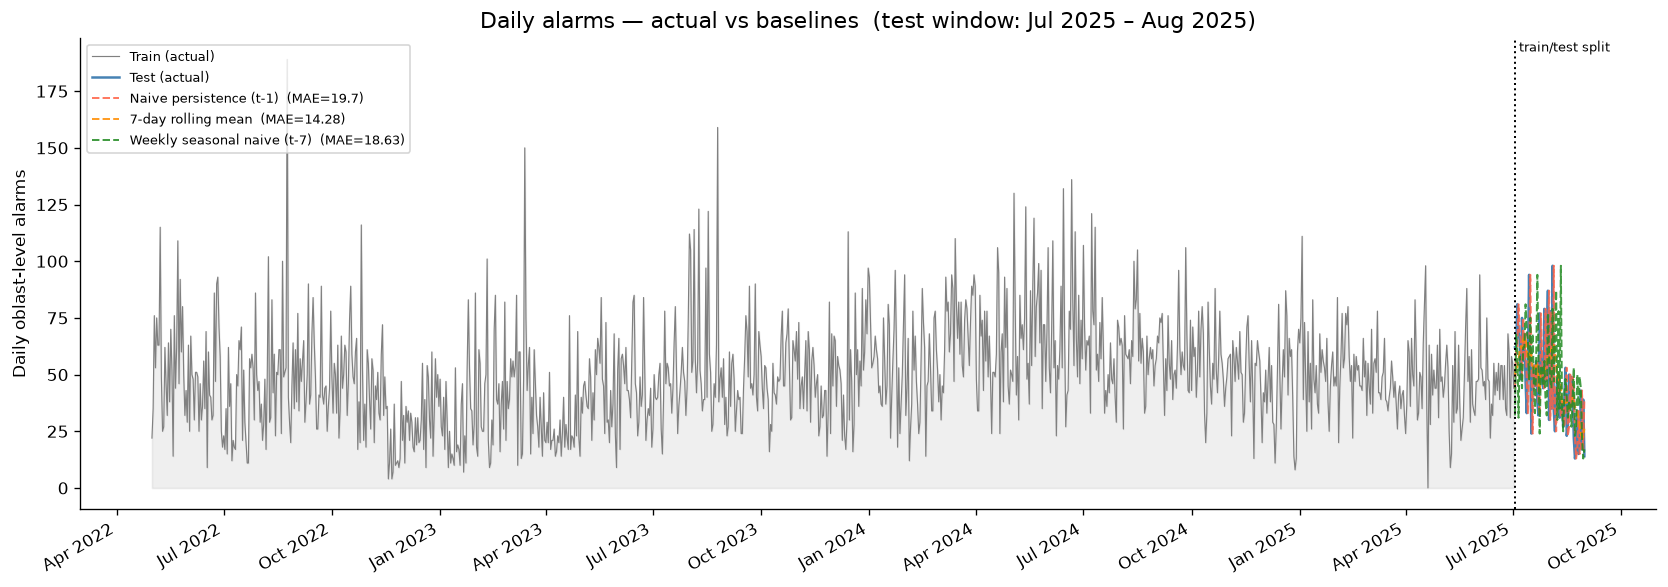

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.fill_between(train.index, preds.loc[train.index, 'actual'], alpha=0.12, color='grey')
ax.plot(train.index, preds.loc[train.index, 'actual'],
        color='grey', linewidth=0.7, label='Train (actual)')
ax.plot(test.index, y_true,
        color='steelblue', linewidth=1.5, label='Test (actual)')

colors = ['tomato', 'darkorange', 'forestgreen']
for (col, label), color in zip(baseline_names.items(), colors):
    mae_val = results_df.loc[label, 'MAE']
    ax.plot(test.index, test_preds[col],
            color=color, linewidth=1.2, linestyle='--', alpha=0.85,
            label=f'{label}  (MAE={mae_val})')

ax.axvline(cutoff, color='black', linewidth=1.2, linestyle=':')
ax.text(cutoff, ax.get_ylim()[1] * 0.97, ' train/test split', fontsize=8)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.xticks(rotation=30, ha='right')
ax.set_ylabel('Daily oblast-level alarms')
ax.set_title(
    f'Daily alarms — actual vs baselines'
    f'  (test window: {test.index.min().strftime("%b %Y")} – {test.index.max().strftime("%b %Y")})',
    fontsize=13,
)
ax.legend(fontsize=8, loc='upper left')
plt.tight_layout()
plt.show()

## Plot 2 — Residuals of the best baseline

Best baseline by MAE: 7-day rolling mean


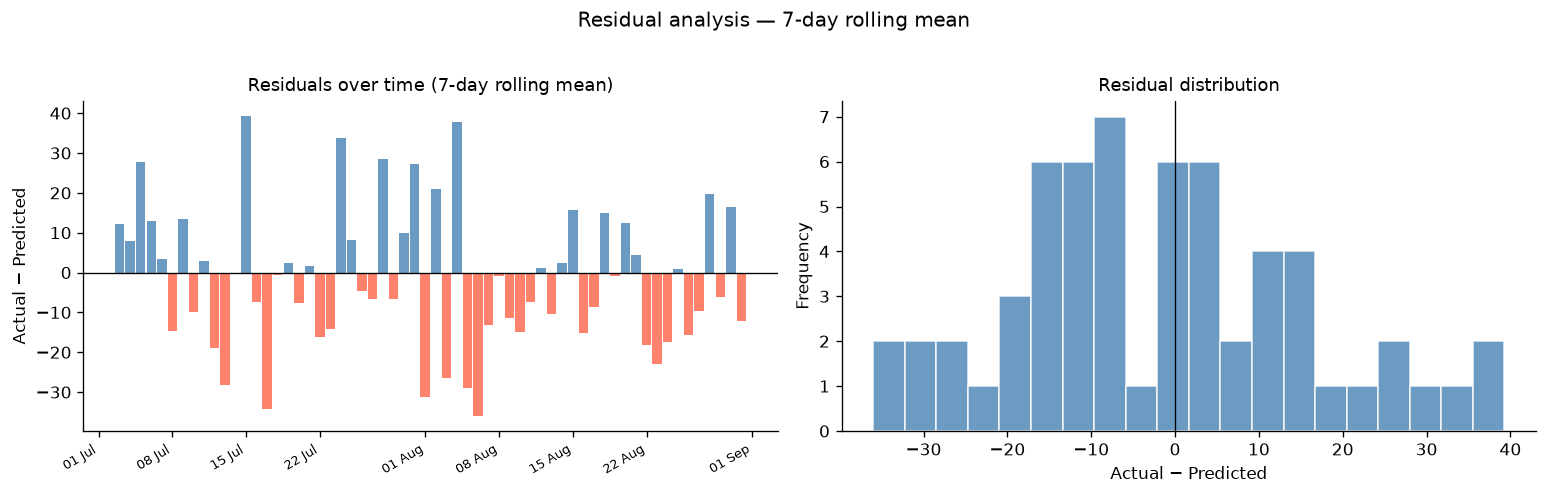

Mean residual : -1.65  (positive = we under-predicted)
Std residual  : 17.76


In [7]:
best_label = results_df['MAE'].idxmin()
best_key   = [k for k, v in baseline_names.items() if v == best_label][0]
print(f'Best baseline by MAE: {best_label}')

residuals = y_true - test_preds[best_key]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(test.index, residuals,
            color=['tomato' if r < 0 else 'steelblue' for r in residuals],
            alpha=0.8, width=0.9)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title(f'Residuals over time ({best_label})', fontsize=11)
axes[0].set_ylabel('Actual − Predicted')
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
plt.setp(axes[0].xaxis.get_majorticklabels(), rotation=30, ha='right', fontsize=8)

axes[1].hist(residuals.dropna(), bins=20, color='steelblue', alpha=0.8, edgecolor='white')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Residual distribution', fontsize=11)
axes[1].set_xlabel('Actual − Predicted')
axes[1].set_ylabel('Frequency')

plt.suptitle(f'Residual analysis — {best_label}', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

print(f'Mean residual : {residuals.mean():.2f}  (positive = we under-predicted)')
print(f'Std residual  : {residuals.std():.2f}')

## Discussion

### Which baseline wins?
See the metrics table above.

### Why is this hard to beat with a simple model?
The daily alarm count is driven by military decisions that are:
- **Non-stationary** — the average level shifts at multiple points across the conflict timeline.
- **Exogenous** — missiles, drones, weather, and strategic priorities are not in this dataset.
- **High-variance** — mass strike events spike the daily count 3–5× overnight.

A rolling mean tracks slow trends but cannot anticipate sudden regime changes.

### What a learnable signal would look like
Calendar features (weekday, month), lagged counts at multiple horizons (1d, 7d, 14d), and — if available — open-source intelligence about missile stockpile replenishment cycles. Even with all of these, the irreducible noise from military uncertainty would keep errors high.

→ Next: `04_reflection.ipynb` for a written synthesis.